# Training code for ping-pong paddle detection

Training only. Fine-tunes pretrained YOLO nano/small models on the Roboflow paddle dataset, compares them, and saves the best `best.pt` to `laptop/models/`. Inference (webcam → MQTT → UNO Q) lives in `vision.py`.

## 1. Config

In [1]:
from pathlib import Path
import shutil

import torch
import yaml
from ultralytics import YOLO

DATASET_DIR = Path("/home/daniel-choate/LEGOEducation/ping-pong/ping-pong.v1i.yolov8")
PROJECT_DIR = Path.cwd()                      # ping-pong/laptop/
RUNS_DIR = PROJECT_DIR / "runs"
MODELS_DIR = PROJECT_DIR / "models"

MODELS = ["yolov8n.pt", "yolov8s.pt"]       # or "yolo11n.pt", "yolo11s.pt"
EPOCHS = 100
PATIENCE = 30                                 # early stop if val mAP stalls
IMGSZ = 640
BATCH = 8
DEVICE = 0 if torch.cuda.is_available() else "cpu"
MAX_VRAM_GB = 6                               # cap PyTorch's GPU memory (8 GB card)

if torch.cuda.is_available():
    total = torch.cuda.get_device_properties(0).total_memory / 1024**3
    torch.cuda.set_per_process_memory_fraction(min(MAX_VRAM_GB / total, 1.0), 0)

print("CUDA:", torch.cuda.is_available(), torch.cuda.get_device_name(0) if torch.cuda.is_available() else "")

CUDA: True NVIDIA GeForce RTX 4060 Laptop GPU


## 2. Dataset check

Roboflow's `data.yaml` uses `../train/images`-style paths that don't resolve from here, so write a corrected copy next to this notebook instead of editing the export.

In [2]:
src = yaml.safe_load((DATASET_DIR / "data.yaml").read_text())
data_cfg = {
    "path": str(DATASET_DIR),
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "names": src["names"],
}
DATA_YAML = PROJECT_DIR / "data.yaml"
DATA_YAML.write_text(yaml.safe_dump(data_cfg, sort_keys=False))
print(DATA_YAML.read_text())

IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp"}
for split in ["train", "valid", "test"]:
    imgs = [p for p in (DATASET_DIR / split / "images").iterdir() if p.suffix.lower() in IMG_EXTS]
    labels = list((DATASET_DIR / split / "labels").glob("*.txt"))
    empty = sum(1 for l in labels if not l.read_text().strip())
    print(f"{split:5s}: {len(imgs):3d} images, {len(labels):3d} labels, {empty} empty (background) label files")

path: /home/daniel-choate/LEGOEducation/ping-pong/ping-pong.v1i.yolov8
train: train/images
val: valid/images
test: test/images
names:
- ping-pong

train:  71 images,  71 labels, 10 empty (background) label files
valid:  19 images,  19 labels, 2 empty (background) label files
test :  10 images,  10 labels, 0 empty (background) label files


## 3. Train

Each model takes a few minutes on GPU. Ultralytics' built-in augmentation is on by default.

In [3]:
run_dirs = {}
for weights in MODELS:
    name = Path(weights).stem
    model = YOLO(weights)
    model.train(
        data=str(DATA_YAML),
        epochs=EPOCHS,
        patience=PATIENCE,
        imgsz=IMGSZ,
        batch=BATCH,
        device=DEVICE,
        project=str(RUNS_DIR),
        name=name,
        exist_ok=True,
        seed=0,
    )
    run_dirs[name] = RUNS_DIR / name

New https://pypi.org/project/ultralytics/8.4.175 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.173 🚀 Python-3.12.13 torch-2.6.0+cu124 CUDA:0 (NVIDIA GeForce RTX 4060 Laptop GPU, 7836MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/daniel-choate/unoq-workspace/ping-pong/laptop/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_de

## 4. Compare on val and test

Pick on **val**; look at **test** once at the end as the honest number. Prefer the smaller model unless the larger one is clearly better (~3–5+ points mAP50-95).

In [4]:
results = {}
for name, run in run_dirs.items():
    model = YOLO(run / "weights" / "best.pt")
    row = {}
    for split in ["val", "test"]:
        m = model.val(data=str(DATA_YAML), split=split, imgsz=IMGSZ, device=DEVICE,
                      project=str(RUNS_DIR), name=f"{name}_{split}", exist_ok=True, verbose=False)
        row[f"{split}_mAP50"] = m.box.map50
        row[f"{split}_mAP50-95"] = m.box.map
    results[name] = row

print(f"{'model':10s} {'val mAP50':>10s} {'val mAP50-95':>13s} {'test mAP50':>11s} {'test mAP50-95':>14s}")
for name, r in results.items():
    print(f"{name:10s} {r['val_mAP50']:10.3f} {r['val_mAP50-95']:13.3f} {r['test_mAP50']:11.3f} {r['test_mAP50-95']:14.3f}")

Ultralytics 8.4.173 🚀 Python-3.12.13 torch-2.6.0+cu124 CUDA:0 (NVIDIA GeForce RTX 4060 Laptop GPU, 7836MiB)
Model summary (fused): 72 layers, 3,005,843 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2412.4±844.7 MB/s, size: 41.6 KB)
val: Scanning /home/daniel-choate/LEGOEducation/ping-pong/ping-pong.v1i.yolov8/valid/labels.cache... 19 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 19/19 8.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 5.4it/s 0.4s0.8s
                   all         19         19          1      0.888      0.968      0.885
Speed: 2.7ms preprocess, 5.2ms inference, 0.0ms loss, 0.4ms postprocess per image
Results saved to /home/daniel-choate/unoq-workspace/ping-pong/laptop/runs/yolov8n_val
Ultralytics 8.4.173 🚀 Python-3.12.13 torch-2.6.0+cu124 CUDA:0 (NVIDIA GeForce RTX 4060 Laptop GPU, 7836MiB)
Model summary (fused): 72 layers, 3,005,843 parameters, 0 

## 5. Visual check on test images

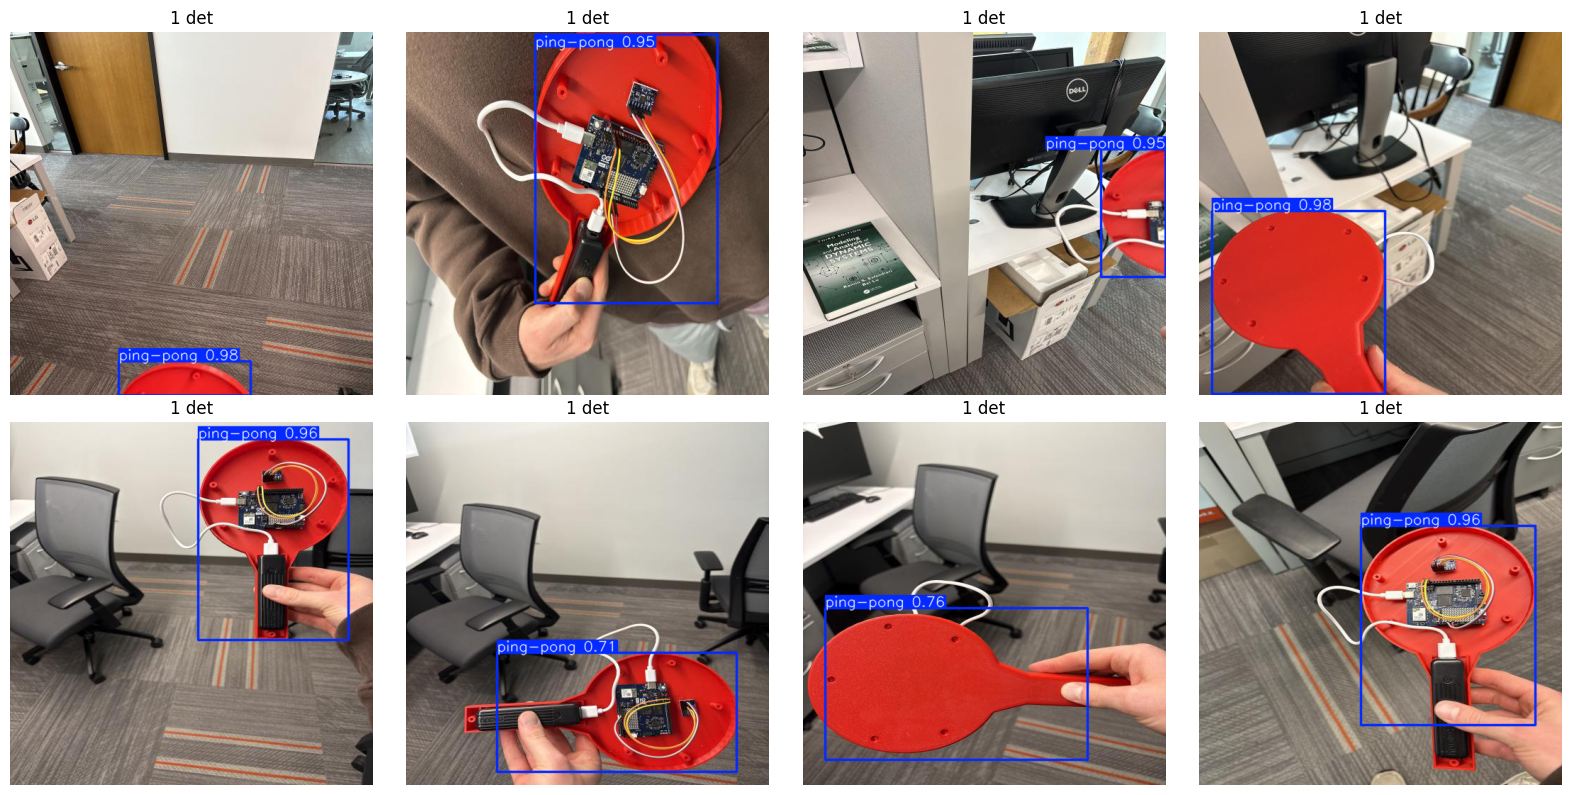

In [5]:
import matplotlib.pyplot as plt

CHOSEN = "yolov8n"   # set after looking at the table above

model = YOLO(run_dirs[CHOSEN] / "weights" / "best.pt")
test_imgs = sorted(p for p in (DATASET_DIR / "test" / "images").iterdir() if p.suffix.lower() in IMG_EXTS)[:8]
preds = model.predict(test_imgs, imgsz=IMGSZ, device=DEVICE, conf=0.25, verbose=False)

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, r in zip(axes.flat, preds):
    ax.imshow(r.plot()[..., ::-1])   # BGR -> RGB
    ax.set_title(f"{len(r.boxes)} det")
    ax.axis("off")
plt.tight_layout()
plt.show()

## 6. Save chosen weights

`vision.py` loads `models/paddle_<model>.pt`.

In [ ]:
MODELS_DIR.mkdir(exist_ok=True)
out = MODELS_DIR / f"paddle_{CHOSEN}.pt"
shutil.copy(run_dirs[CHOSEN] / "weights" / "best.pt", out)
print("Saved", out)

## 7. Live webcam test

Sanity check of the saved weights on the laptop webcam. Only needs cell 1 run first (no retraining). The frame is mirrored so moving right moves right on screen, and split into the game's 3 zones; the paddle's zone is highlighted. Press **q** in the window (or interrupt the kernel) to stop.

In [ ]:
import cv2

WEIGHTS = MODELS_DIR / "paddle_yolov8n.pt"
CAMERA = 0      # try 1, 2, ... if the wrong camera opens
CONF = 0.5
ZONES = ["left", "center", "right"]

model = YOLO(WEIGHTS)
cap = cv2.VideoCapture(CAMERA)
if not cap.isOpened():
    raise RuntimeError(f"Could not open camera {CAMERA}")

try:
    while True:
        ok, frame = cap.read()
        if not ok:
            break
        frame = cv2.flip(frame, 1)   # mirror
        h, w = frame.shape[:2]

        r = model.predict(frame, imgsz=IMGSZ, device=DEVICE, conf=CONF, verbose=False)[0]
        vis = r.plot()
        for i in (1, 2):
            cv2.line(vis, (w * i // 3, 0), (w * i // 3, h), (255, 255, 255), 2)

        if len(r.boxes):
            best = r.boxes[r.boxes.conf.argmax()]          # most confident paddle
            cx, cy = best.xywh[0][:2].tolist()
            z = min(int(cx / w * 3), 2)
            cv2.rectangle(vis, (w * z // 3, 0), (w * (z + 1) // 3, h), (0, 255, 0), 4)
            cv2.circle(vis, (int(cx), int(cy)), 6, (0, 0, 255), -1)
            text = f"zone={ZONES[z]}  cx={cx / w:.2f}  conf={float(best.conf):.2f}"
        else:
            text = "no paddle"
        fps = 1000 / sum(r.speed.values())
        cv2.putText(vis, f"{text}  {fps:.0f} fps", (10, 30), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 255), 2)

        cv2.imshow("paddle live (q to quit)", vis)
        if cv2.waitKey(1) & 0xFF == ord("q"):
            break
finally:
    cap.release()
    cv2.destroyAllWindows()